<a href="https://colab.research.google.com/github/marwann3/databuddy-agent/blob/main/data_analyst_agent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DataBuddy: an Agentic Data Analyst with LlamaIndex

An agent that answers questions about a CSV file (totals, rankings, filters, charts) by **calling tools instead of guessing numbers**.



## 1. Use case

**Problem:** business users have sales data in a CSV but cannot write pandas or SQL. They want to ask in plain language: *"Which region earns the most?"*, *"Plot revenue by category"*.

**Why an agent, not a plain LLM or a fixed script?**
- A plain LLM cannot see the data, so it would hallucinate numbers.
- A fixed script only answers the questions it was coded for.
- An agent decides **which tool** to call and **in what order**, reads the result, and retries when a call fails. Multi-step questions ("compare Cairo and Delta, then plot it") work naturally.

## 2. Choose the LLM and provider

| Choice | Value |
|---|---|
| Model | `llama-3.3-70b-versatile` (Meta Llama 3.3 70B) |
| Provider | Groq (free tier, OpenAI-compatible API) |
| Agent loop | Native function calling |
| Temperature | 0.1 |



In [ ]:
%pip install -q "llama-index-core>=0.14.25,<0.15" llama-index-llms-openai-like pandas matplotlib python-dotenv

### Setup: Groq API key

Get a free key at console.groq.com/keys. It is read from Colab **Secrets** (`GROQ_API_KEY`). It is never written in the notebook, so it is safe to push to GitHub. Outside Colab it falls back to an environment variable or a prompt.

In [ ]:
import os, getpass

try:
    from google.colab import userdata
    os.environ["GROQ_API_KEY"] = userdata.get("GROQ_API_KEY")
except Exception:
    if not os.getenv("GROQ_API_KEY"):
        os.environ["GROQ_API_KEY"] = getpass.getpass("Groq API key: ")

print("GROQ_API_KEY set:", bool(os.getenv("GROQ_API_KEY")))

GROQ_API_KEY set: True


In [ ]:
import os
os.environ["GROQ_MODEL"] = "openai/gpt-oss-120b"

### Sample dataset

A small synthetic sales dataset (240 rows) is generated here, so there is nothing to upload.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
regions = ["Cairo", "Alexandria", "Delta", "Upper Egypt"]
cats = {"Electronics": ["Laptop", "Phone", "Headphones"],
        "Furniture": ["Desk", "Chair", "Shelf"],
        "Office": ["Notebook", "Printer", "Pens"]}
price = {"Laptop": 18000, "Phone": 12000, "Headphones": 1500, "Desk": 4500, "Chair": 2500,
         "Shelf": 1800, "Notebook": 60, "Printer": 5000, "Pens": 30}
dates = pd.date_range("2025-01-01", "2025-12-31")

rows = []
for _ in range(240):
    c = str(rng.choice(list(cats)))
    p = str(rng.choice(cats[c]))
    u = int(rng.integers(1, 15))
    up = price[p]
    rows.append((dates[int(rng.integers(len(dates)))].strftime("%Y-%m-%d"),
                 str(rng.choice(regions)), c, p, u, up, u * up))

Path("data").mkdir(exist_ok=True)
pd.DataFrame(rows, columns=["date", "region", "category", "product", "units", "unit_price", "revenue"]) \
  .sort_values("date").to_csv("data/sales.csv", index=False)
print(pd.read_csv("data/sales.csv").head())

         date       region     category     product  units  unit_price  \
0  2025-01-03  Upper Egypt       Office    Notebook     12          60   
1  2025-01-06  Upper Egypt       Office        Pens      3          30   
2  2025-01-06   Alexandria       Office    Notebook      3          60   
3  2025-01-09  Upper Egypt    Furniture       Chair      5        2500   
4  2025-01-10        Delta  Electronics  Headphones     12        1500   

   revenue  
0      720  
1       90  
2      180  
3    12500  
4    18000  


## 3. Tools (designed for this use case)

| Tool | Purpose | Key arguments |
|---|---|---|
| `describe_dataset` | Shape, columns, dtypes, first rows. Called first to learn exact column names | none |
| `column_summary` | Stats for numeric columns, top values for text columns, missing values | `column` |
| `aggregate` | Group by a column and sum/mean/count/min/max/median another | `group_by`, `value_column`, `agg`, `top_n` |
| `filter_rows` | Look at specific records (`==`, `!=`, `>`, `<`, `>=`, `<=`, `contains`) | `column`, `operator`, `value`, `limit` |
| `plot_chart` | Save a bar/line/pie chart as PNG | `kind`, `x`, `y`, `agg` |

**Design decisions**
- **Few, focused tools**, so the model picks the right one easily.
- **Docstrings are written for the model.** LlamaIndex uses the function name, type hints and docstring as the tool schema.
- **Tools never crash.** On bad input they return an error that lists the valid options, so the agent can correct itself.
- **No arbitrary code execution.** The agent cannot run free-form Python, which keeps it safe.

In [ ]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

DATA_PATH = "data/sales.csv"
OUTPUT_DIR = Path("outputs")
VALID_AGGS = ["sum", "mean", "count", "min", "max", "median"]
VALID_OPS = ["==", "!=", ">", "<", ">=", "<=", "contains"]
VALID_CHARTS = ["bar", "line", "pie"]

_df = None


def _load() -> pd.DataFrame:
    global _df
    if _df is None:
        _df = pd.read_csv(DATA_PATH)
    return _df


def _bad_column(name: str, df: pd.DataFrame) -> str:
    return f"Error: column '{name}' does not exist. Valid columns: {list(df.columns)}"


def describe_dataset() -> str:
    """Show the dataset's shape, column names, data types and the first 5 rows.
    Always call this first, before any other tool, to learn the exact column names."""
    df = _load()
    return (f"Rows: {len(df)}, Columns: {len(df.columns)}\n"
            f"Dtypes:\n{df.dtypes.to_string()}\n\n"
            f"First 5 rows:\n{df.head().to_string(index=False)}")


def column_summary(column: str) -> str:
    """Summarize ONE column: statistics (mean, min, max, ...) for numeric columns,
    or the most frequent values for text columns. Also reports missing values."""
    df = _load()
    if column not in df.columns:
        return _bad_column(column, df)
    s = df[column]
    out = f"Column '{column}' | missing values: {int(s.isna().sum())}\n"
    if pd.api.types.is_numeric_dtype(s):
        return out + s.describe().to_string()
    return out + f"Unique values: {s.nunique()}\nTop values:\n{s.value_counts().head(10).to_string()}"


def aggregate(group_by: str, value_column: str, agg: str = "sum", top_n: int = 10) -> str:
    """Group the data by one column and aggregate a numeric column.
    agg must be one of: sum, mean, count, min, max, median.
    Example: aggregate(group_by='region', value_column='revenue', agg='sum')
    Returns the groups sorted from highest to lowest, limited to top_n rows."""
    df = _load()
    for col in (group_by, value_column):
        if col not in df.columns:
            return _bad_column(col, df)
    if agg not in VALID_AGGS:
        return f"Error: agg '{agg}' is invalid. Use one of: {VALID_AGGS}"
    if agg != "count" and not pd.api.types.is_numeric_dtype(df[value_column]):
        return f"Error: '{value_column}' is not numeric, so '{agg}' is not possible. Use agg='count'."
    result = df.groupby(group_by)[value_column].agg(agg).sort_values(ascending=False).head(top_n)
    return f"{agg}({value_column}) by {group_by}:\n{result.round(2).to_string()}"


def filter_rows(column: str, operator: str, value: str, limit: int = 10) -> str:
    """Return rows where `column <operator> value`.
    operator must be one of: ==, !=, >, <, >=, <=, contains.
    Also reports how many rows matched in total. Example:
    filter_rows(column='region', operator='==', value='Cairo')"""
    df = _load()
    if column not in df.columns:
        return _bad_column(column, df)
    if operator not in VALID_OPS:
        return f"Error: operator '{operator}' is invalid. Use one of: {VALID_OPS}"
    s = df[column]
    try:
        if operator == "contains":
            mask = s.astype(str).str.contains(str(value), case=False, regex=False)
        else:
            v = float(value) if pd.api.types.is_numeric_dtype(s) else str(value)
            mask = {"==": s == v, "!=": s != v, ">": s > v, "<": s < v, ">=": s >= v, "<=": s <= v}[operator]
    except (ValueError, TypeError):
        return f"Error: cannot compare column '{column}' with value '{value}'."
    res = df[mask]
    if res.empty:
        return "No rows matched."
    return f"{len(res)} rows matched. Showing up to {limit}:\n{res.head(limit).to_string(index=False)}"


def plot_chart(kind: str, x: str, y: str, agg: str = "sum") -> str:
    """Create a chart and save it as a PNG file. kind must be: bar, line or pie.
    x is the grouping column, y is the numeric column, agg is how y is combined per x
    (sum, mean, count, min, max, median). Returns the path of the saved image.
    Example: plot_chart(kind='bar', x='category', y='revenue', agg='sum')"""
    df = _load()
    for col in (x, y):
        if col not in df.columns:
            return _bad_column(col, df)
    if kind not in VALID_CHARTS:
        return f"Error: kind '{kind}' is invalid. Use one of: {VALID_CHARTS}"
    if agg not in VALID_AGGS:
        return f"Error: agg '{agg}' is invalid. Use one of: {VALID_AGGS}"
    data = df.groupby(x)[y].agg(agg)
    if kind == "line":
        data = data.sort_index()
    fig, ax = plt.subplots(figsize=(8, 5))
    if kind == "pie":
        data.plot.pie(ax=ax, autopct="%1.1f%%", ylabel="")
    else:
        data.plot(kind=kind, ax=ax)
        ax.set_xlabel(x)
        ax.set_ylabel(f"{agg}({y})")
    ax.set_title(f"{agg}({y}) by {x}")
    fig.tight_layout()
    OUTPUT_DIR.mkdir(exist_ok=True)
    path = OUTPUT_DIR / f"{kind}_{agg}_{y}_by_{x}.png"
    fig.savefig(path, dpi=120)
    plt.close(fig)
    return f"Chart saved to {path}"


ALL_TOOLS = [describe_dataset, column_summary, aggregate, filter_rows, plot_chart]

### Quick test of the tools (no LLM needed)

This confirms the tools work, including the self-correcting error message for a wrong column name.

In [ ]:
print(aggregate("region", "revenue", "sum"))
print()
print(aggregate("regionn", "revenue"))  # wrong name on purpose
print()
print(filter_rows("units", ">", "13", limit=3))

sum(revenue) by region:
region
Cairo          2199750
Upper Egypt    1901780
Alexandria     1780150
Delta          1767650

Error: column 'regionn' does not exist. Valid columns: ['date', 'region', 'category', 'product', 'units', 'unit_price', 'revenue']

14 rows matched. Showing up to 3:
      date     region    category    product  units  unit_price  revenue
2025-03-07      Cairo Electronics Headphones     14        1500    21000
2025-03-29 Alexandria      Office       Pens     14          30      420
2025-03-29      Cairo Electronics Headphones     14        1500    21000


## 4. System prompt

Main ideas:
- Role and goal: data analyst for one CSV.
- Must call `describe_dataset` first, so it never guesses column names.
- **Never invent numbers**: every number must come from a tool result.
- Retry with corrected arguments when a tool returns an error.
- Say clearly when the dataset cannot answer the question.
- Short answers, direct answer first, reply in the user's language.

In [ ]:
SYSTEM_PROMPT = """You are DataBuddy, a data analyst assistant for a single CSV dataset.

# Goal
Answer the user's questions about the dataset accurately, using the tools you are given.

# Rules
1. Always call `describe_dataset` first if you have not yet seen the column names in this conversation.
2. NEVER guess or invent numbers. Every number in your answer must come from a tool result.
3. Use `aggregate` for totals, averages and rankings, `filter_rows` to look at specific records,
   `column_summary` to understand one column, and `plot_chart` ONLY when the user asks for a chart or visual.
4. If a tool returns an error, read the valid options in the error message and retry with corrected arguments.
   Do not give up after one failed call.
5. Break multi-part questions into separate tool calls, then combine the results into one answer.
6. If the question cannot be answered from this dataset (for example, data that is not in the columns),
   say so clearly instead of making something up.

# Answer style
- Start with the direct answer in one sentence, then give supporting numbers.
- Keep it short. Use a small list or table only when comparing several values.
- If you created a chart, mention the file path.
- Answer in the same language the user wrote in.
"""

## 5. Implementation with LlamaIndex

- `FunctionTool` wraps each Python function as a tool.
- `OpenAILike` connects LlamaIndex to Groq's OpenAI-compatible API.
- `AgentWorkflow.from_tools_or_functions` builds the agent. Because the LLM is marked as a function-calling model, LlamaIndex uses a `FunctionAgent` (native tool calls).
- `Context` gives the agent **memory** across questions.

In [ ]:
from llama_index.core.agent.workflow import AgentWorkflow
from llama_index.core.tools import FunctionTool
from llama_index.core.workflow import Context
from llama_index.llms.openai_like import OpenAILike

LLM_MODEL = os.getenv("GROQ_MODEL", "llama-3.3-70b-versatile")

llm = OpenAILike(
    model=LLM_MODEL,
    api_base="https://api.groq.com/openai/v1",
    api_key=os.getenv("GROQ_API_KEY"),
    is_chat_model=True,
    is_function_calling_model=True,  # native tool calling -> FunctionAgent
    context_window=32768,
    temperature=0.1,                 # low temperature: accurate, repeatable analysis
    max_tokens=512,
)

tools = [FunctionTool.from_defaults(fn) for fn in ALL_TOOLS]

agent = AgentWorkflow.from_tools_or_functions(tools, llm=llm, system_prompt=SYSTEM_PROMPT)
ctx = Context(agent)  # conversation memory
print("Agent ready with tools:", [t.metadata.name for t in tools])

Agent ready with tools: ['describe_dataset', 'column_summary', 'aggregate', 'filter_rows', 'plot_chart']


## Try it

If a call fails because the model name is no longer available on Groq, set `os.environ["GROQ_MODEL"]` to another model from console.groq.com/docs/models (for example `openai/gpt-oss-120b`), then re-run the agent cell. On the free tier you may see a rate-limit (429) message; wait a minute and re-run.

In [ ]:
print(await agent.run("Which region has the highest total revenue?", ctx=ctx))

Cairo has the highest total revenue, with a sum of **2,199,750**.


In [ ]:
print(await agent.run("What are the top 3 products by units sold?", ctx=ctx))

/usr/local/lib/python3.13/dist-packages/workflows/context/state_store.py:231: UnserializableKeyWarning: Skipping serialization of known unserializable key: memory -- This is expected but will require this item to be set manually after deserialization.
  warnings.warn(


The top 3 products by total units sold are:

| Rank | Product     | Units Sold |
|------|------------|------------|
| 1    | Headphones | 257 |
| 2    | Pens       | 221 |
| 3    | Printer    | 215 |


In [ ]:
# Follow-up question: shows the agent's memory
print(await agent.run("And what about by revenue?", ctx=ctx))

/usr/local/lib/python3.13/dist-packages/workflows/context/state_store.py:231: UnserializableKeyWarning: Skipping serialization of known unserializable key: memory -- This is expected but will require this item to be set manually after deserialization.
  warnings.warn(


By total revenue, the regions rank as follows:

| Rank | Region       | Revenue |
|------|--------------|---------|
| 1    | Cairo        | 2,199,750 |
| 2    | Upper Egypt  | 1,901,780 |
| 3    | Alexandria   | 1,780,150 |
| 4    | Delta        | 1,767,650 |

Cairo has the highest revenue, followed by Upper Egypt, Alexandria, and Delta.


In [ ]:
print(await agent.run("Plot revenue by category as a bar chart.", ctx=ctx))

/usr/local/lib/python3.13/dist-packages/workflows/context/state_store.py:231: UnserializableKeyWarning: Skipping serialization of known unserializable key: memory -- This is expected but will require this item to be set manually after deserialization.
  warnings.warn(


Revenue by category (sum) is shown in the bar chart saved at **outputs/bar_sum_revenue_by_category.png**.


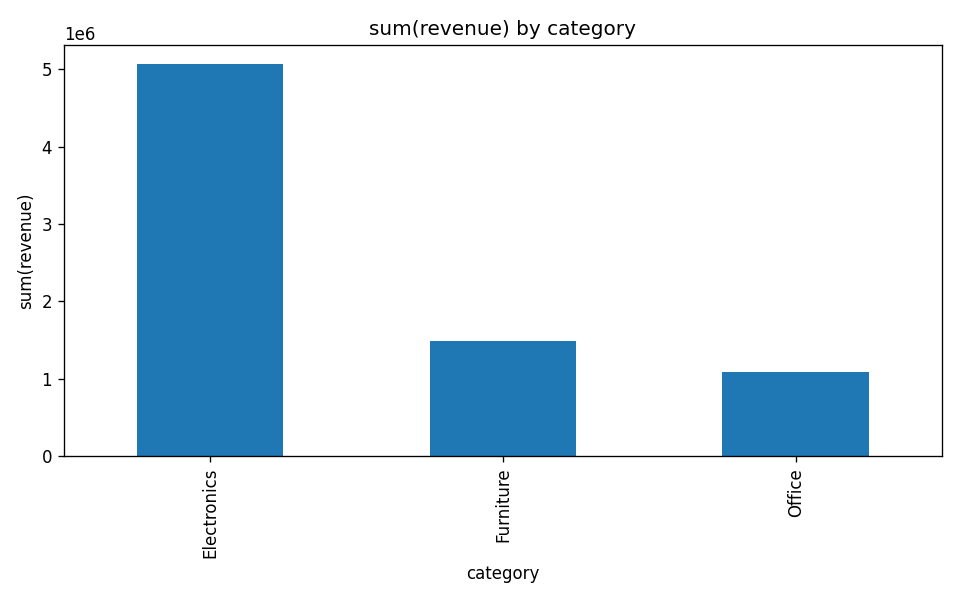

In [ ]:
from IPython.display import Image, display
display(Image("outputs/bar_sum_revenue_by_category.png"))

## Summary

| Step | What was done |
|---|---|
| 1. Use case | Data analyst agent for CSV files |
| 2. LLM and provider | Llama 3.3 70B (`llama-3.3-70b-versatile`) on Groq free tier |
| 3. Tools | `describe_dataset`, `column_summary`, `aggregate`, `filter_rows`, `plot_chart` |
| 4. System prompt | Role, rules (never invent numbers, retry on errors), answer style |
| 5. Implementation | LlamaIndex `AgentWorkflow` (function calling) with `FunctionTool`, `OpenAILike` and `Context` memory |